# 28 — Histórico institucional com contexto do calendário

Teste limitado motivado pelos erros de julho já observados. Continua exploratório: 2026 já foi examinado. Registrar a regra antes desta execução não torna o período uma confirmação independente.

A referência usa mediana dos últimos até oito quantitativos de 2026 dentro dos 120 dias anteriores à origem, do mesmo dia da semana e contexto. Contexto combina fase de férias/recesso, tipo de evento e proximidade imediata de feriado. Menos de três comparáveis: modelo puro. Com três a cinco, contribuição reduzida; a partir de seis, permite o limite escolhido entre 0%, 25%, 50% e 75%. Não há novas buscas de janela ou classe depois da conferência.

O estimador permanece treinado em 2023–2025. Peso e margens são escolhidos em 36 datas de março–abril de 2026; maio é intervalo de disponibilidade; a conferência conserva as 43 datas de junho–agosto do teste anterior. A condição mensal mantém o consumo do mês anterior indisponível. Quantitativos históricos têm corte por data de refeição, sem comprovação de recebimento individual; o calendário anual é considerado disponível, sem versões históricas datadas.


In [1]:
from pathlib import Path
import subprocess,sys,os,json
import pandas as pd
from IPython.display import display,Image
ROOT=Path(r"F:\PRODUTO_MESTRADO")
OUT=ROOT/"resultados/contexto_institucional_20261003"
env=dict(os.environ,PYTHONIOENCODING="utf-8",PYTHONDONTWRITEBYTECODE="1")
for script in ["testar_contexto_institucional.py","complementar_contexto_institucional.py"]:
    run=subprocess.run([sys.executable,str(ROOT/"scripts"/script)],cwd=ROOT,env=env,capture_output=True,text=True,encoding="utf-8")
    print(run.stdout)
    if run.returncode:raise RuntimeError(run.stderr)


Etapa preservada; hashes conferidos.
horizonte                             metodo  n_datas  MAE_refeicoes  WAPE_pct  vies_refeicoes  excesso_potencial  deficit_potencial  dias_deficit  perda_hipotetica_2a1  dias_sem_deficit_pct  perda_hipotetica_9a1
  Semanal                        Modelo puro       43          44.00     27.05           -8.33              767.0             1125.0            31                 70.16                 27.91                253.30
   Mensal                        Modelo puro       43          51.05     31.38          -10.02              882.0             1313.0            32                 81.58                 25.58                295.33
  Semanal      Histórico anterior sem margem       43          44.09     27.11            8.56             1132.0              764.0            26                 61.86                 39.53                186.23
   Mensal      Histórico anterior sem margem       43          47.00     28.90           22.91             1503

{"avaliado_em": "2026-10-03T15:06:51-03:00", "n_consumos_aprovados": 0, "n_datas_consumo_nas_emissoes": 0, "previsoes_recalculadas": false, "quantitativo_alvo_necessario_previsao": false, "limite": "Antecedência distinta entre previsão antecipada e quantitativo recebido; excesso/déficit potenciais."}



In [2]:
display(json.loads((OUT/"politicas_selecionadas.json").read_text(encoding="utf-8")))
for name in ["metricas_selecao.csv","metricas_conferencia.csv","metricas_mensais_conferencia.csv","metricas_por_contexto.csv","suporte_historico.csv"]:
    print(name)
    display(pd.read_csv(OUT/name).round(2))
display(pd.read_csv(OUT/"diagnosticos/metricas_controles.csv").round(2))


{'Semanal': {'limite_peso_historico': 0.25,
  'moderado': {'regra': 'P67 próprio',
   'valor': 29.925270010756556,
   'n_erros': 36,
   'perda_selecao': 39.888888888888886},
  'conservador': {'regra': 'P90 próprio',
   'valor': 74.1493073378202,
   'n_erros': 36,
   'perda_selecao': 65.05555555555556},
  'n_selecao': 36,
  'dados_consumo_antes': '2026-05-01'},
 'Mensal': {'limite_peso_historico': 0.75,
  'moderado': {'regra': 'P67 próprio',
   'valor': 49.717684180786165,
   'n_erros': 36,
   'perda_selecao': 46.47222222222222},
  'conservador': {'regra': 'P90 próprio',
   'valor': 87.79830771871343,
   'n_erros': 36,
   'perda_selecao': 80.16666666666667},
  'n_selecao': 36,
  'dados_consumo_antes': '2026-05-01'}}

metricas_selecao.csv


,horizonte,limite_peso_historico,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1,dias_sem_deficit_pct,perda_hipotetica_9a1
0,Semanal,0.00,36,31.69,17.98,-20.19,207.0,934.0,24,57.64,33.33,239.25
1,Semanal,0.25,36,31.50,17.87,-19.83,210.0,924.0,23,57.17,36.11,236.83
2,Semanal,0.50,36,31.56,17.90,-19.44,218.0,918.0,23,57.06,36.11,235.56
3,Semanal,0.75,36,31.61,17.93,-19.11,225.0,913.0,23,56.97,36.11,234.50
4,Mensal,0.00,36,43.03,24.41,-38.97,73.0,1476.0,29,84.03,19.44,371.03
5,Mensal,0.25,36,42.53,24.12,-38.47,73.0,1458.0,29,83.03,19.44,366.53
6,Mensal,0.50,36,42.00,23.82,-37.94,73.0,1439.0,29,81.97,19.44,361.78
7,Mensal,0.75,36,41.72,23.66,-37.39,78.0,1424.0,28,81.28,22.22,358.17


metricas_conferencia.csv


,horizonte,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1,dias_sem_deficit_pct,perda_hipotetica_9a1
0,Semanal,Modelo puro,43,44.00,27.05,-8.33,767.0,1125.0,31,70.16,27.91,253.30
1,Mensal,Modelo puro,43,51.05,31.38,-10.02,882.0,1313.0,32,81.58,25.58,295.33
2,Semanal,Histórico anterior sem margem,43,44.09,27.11,8.56,1132.0,764.0,26,61.86,39.53,186.23
3,Mensal,Histórico anterior sem margem,43,47.00,28.90,22.91,1503.0,518.0,16,59.05,62.79,143.37
4,Semanal,Histórico anterior moderado,43,42.42,26.08,18.56,1311.0,513.0,24,54.35,44.19,137.86
5,Mensal,Histórico anterior moderado,43,48.05,29.54,26.70,1607.0,459.0,15,58.72,65.12,133.44
6,Semanal,Quantitativo real da nutricionista,43,29.79,18.32,20.95,1091.0,190.0,15,34.21,65.12,65.14
7,Mensal,Quantitativo real da nutricionista,43,29.79,18.32,20.95,1091.0,190.0,15,34.21,65.12,65.14
8,Semanal,Contexto sem margem,43,42.02,25.84,-3.65,825.0,982.0,30,64.86,30.23,224.72
9,Mensal,Contexto sem margem,43,44.93,27.62,6.37,1103.0,829.0,23,64.21,46.51,199.16


...

metricas_por_contexto.csv


,horizonte,fase,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1,dias_sem_deficit_pct,perda_hipotetica_9a1
0,Semanal,Retorno de férias/recesso,Modelo puro,8,34.25,24.08,0.75,140.0,134.0,5,51.00,37.50,168.25
1,Semanal,Período regular,Modelo puro,32,42.25,23.93,-19.69,361.0,991.0,26,73.22,18.75,290.00
2,Semanal,Antes de férias/recesso,Modelo puro,3,88.67,128.50,88.67,266.0,0.0,0,88.67,100.00,88.67
3,Mensal,Retorno de férias/recesso,Modelo puro,8,42.25,29.70,12.25,218.0,120.0,5,57.25,37.50,162.25
4,Mensal,Período regular,Modelo puro,32,48.75,27.62,-25.81,367.0,1193.0,27,86.03,15.62,347.00
5,Mensal,Antes de férias/recesso,Modelo puro,3,99.00,143.48,99.00,297.0,0.0,0,99.00,100.00,99.00
6,Semanal,Retorno de férias/recesso,Histórico anterior sem margem,8,40.00,28.12,26.75,267.0,53.0,3,46.62,62.50,93.00
7,Semanal,Período regular,Histórico anterior sem margem,32,36.69,20.78,-7.75,463.0,711.0,23,58.91,28.12,214.44
8,Semanal,Antes de férias/recesso,Histórico anterior sem margem,3,134.00,194.20,134.00,402.0,0.0,0,134.00,100.00,134.00
9,Mensal,Retorno de férias/recesso,Histórico anterior sem margem,8,44.62,31.37,34.88,318.0,39.0,3,49.50,62.50,83.62


suporte_historico.csv


,horizonte,mes,n_datas,n_combinadas,peso_medio,amostra_media
0,Mensal,6,17,10,0.36,3.24
1,Mensal,7,6,0,0.00,0.33
2,Mensal,8,20,17,0.49,4.15
3,Semanal,6,17,10,0.12,3.35
4,Semanal,7,6,0,0.00,0.33
5,Semanal,8,20,17,0.18,4.50


,horizonte,controle,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1,dias_sem_deficit_pct,perda_hipotetica_9a1
0,Semanal,Sem margem,Modelo puro,43,44.00,27.05,-8.33,767.0,1125.0,31,70.16,27.91,253.30
1,Mensal,Sem margem,Modelo puro,43,51.05,31.38,-10.02,882.0,1313.0,32,81.58,25.58,295.33
2,Semanal,Sem margem,Histórico anterior sem margem,43,44.09,27.11,8.56,1132.0,764.0,26,61.86,39.53,186.23
3,Mensal,Sem margem,Histórico anterior sem margem,43,47.00,28.90,22.91,1503.0,518.0,16,59.05,62.79,143.37
4,Semanal,Sem margem,Contexto sem margem,43,42.02,25.84,-3.65,825.0,982.0,30,64.86,30.23,224.72
5,Mensal,Sem margem,Contexto sem margem,43,44.93,27.62,6.37,1103.0,829.0,23,64.21,46.51,199.16
6,Semanal,Mesma +10,Modelo puro,43,40.00,24.59,1.67,896.0,824.0,28,59.16,34.88,193.30
7,Mensal,Mesma +10,Modelo puro,43,46.81,28.78,-0.02,1006.0,1007.0,30,70.23,30.23,234.16
8,Semanal,Mesma +10,Histórico anterior sem margem,43,42.42,26.08,18.56,1311.0,513.0,24,54.35,44.19,137.86
9,Mensal,Mesma +10,Histórico anterior sem margem,43,50.12,30.81,32.91,1785.0,370.0,13,58.72,69.77,118.95


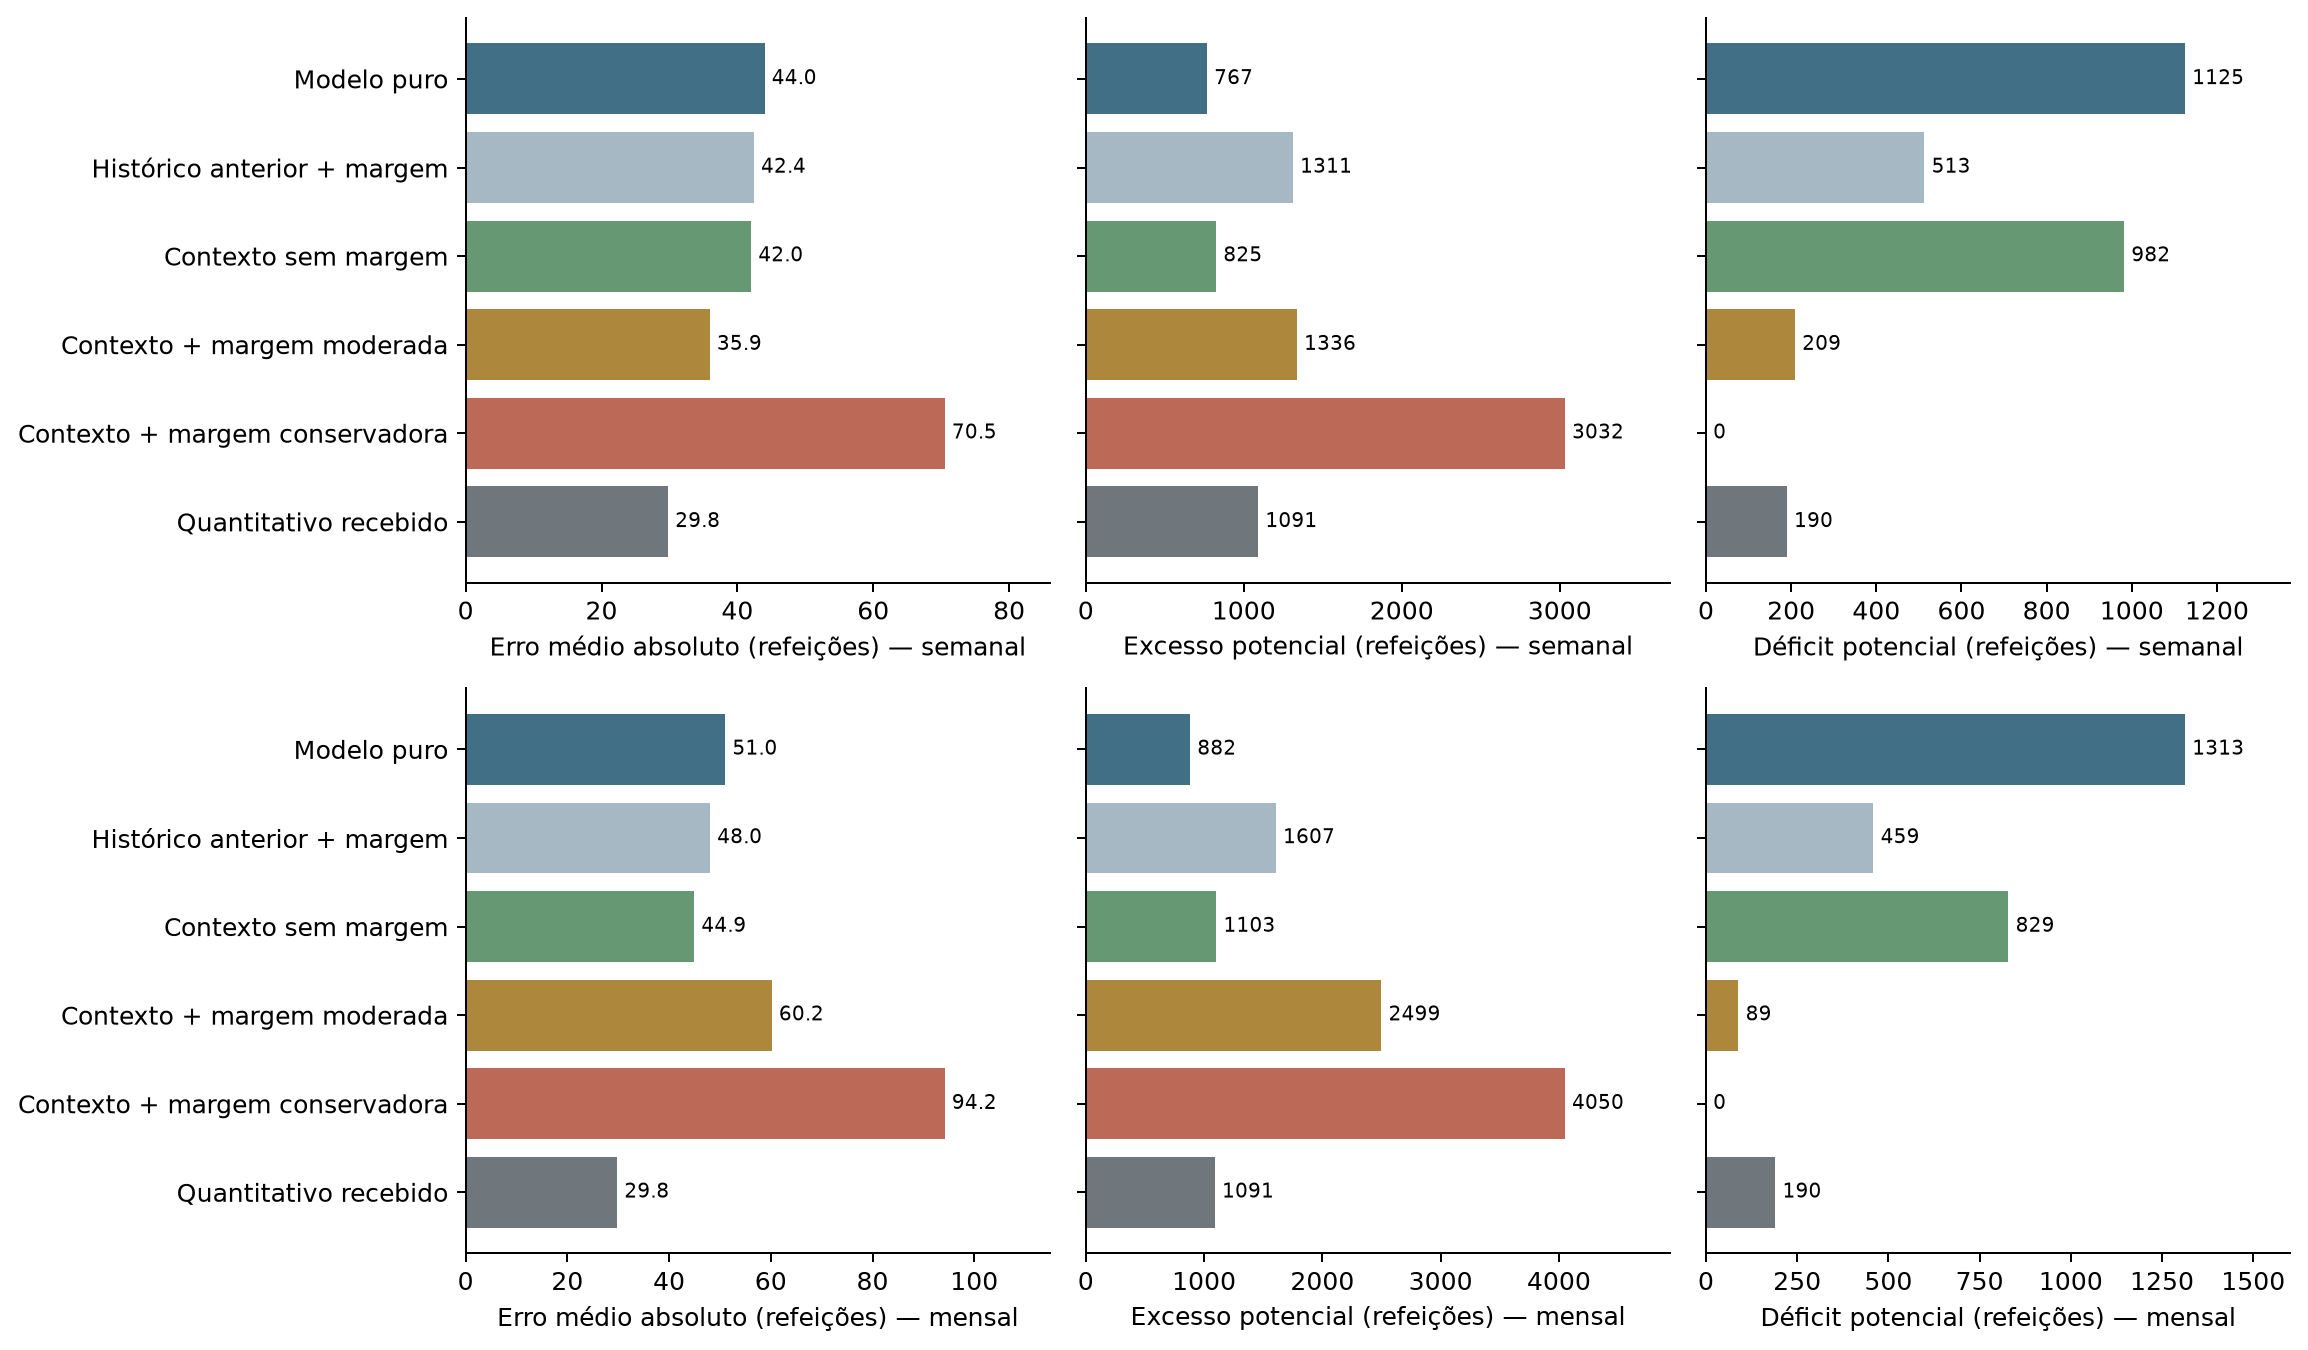

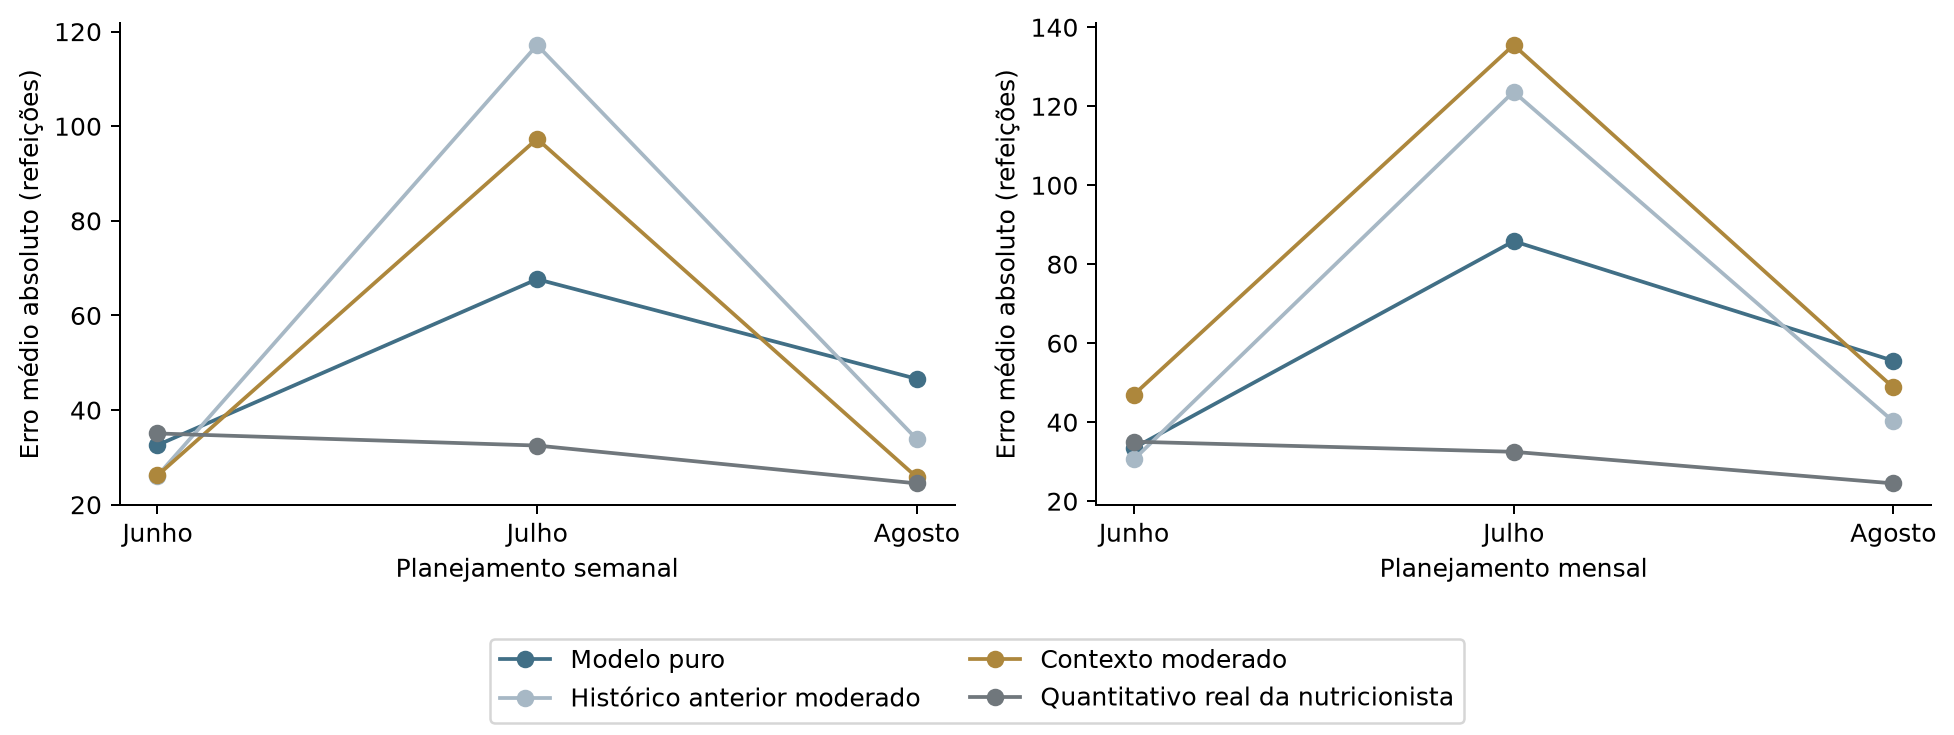

In [3]:
display(Image(filename=str(OUT/"figuras/comparacao_contexto.png")))
display(Image(filename=str(OUT/"figuras/erro_contexto_por_mes.png")))


In [4]:
for name in ["semanal_20261005_20261009","mensal_20261003"]:
    print(name)
    display(pd.read_csv(OUT/"emissoes_outubro"/name/"cenarios_para_gestao.csv",sep=";"))
    display(pd.read_csv(OUT/"emissoes_outubro"/name/"previsoes_congeladas.csv")[["data","contexto","n_comparaveis","peso_historico","fonte"]])
display(json.loads((OUT/"checagens.json").read_text(encoding="utf-8")))
display(json.loads((OUT/"confrontos/status_avaliacao.json").read_text(encoding="utf-8")))


semanal_20261005_20261009


,Data,Dia da semana,Modelo puro,Contexto sem margem,Moderado,Conservador contra falta
0,05/10/2026,segunda-feira,182,182,212,256
1,06/10/2026,terça-feira,171,171,201,245
2,07/10/2026,quarta-feira,173,173,203,247
3,08/10/2026,quinta-feira,168,168,198,242
4,09/10/2026,sexta-feira,173,173,203,247


,data,contexto,n_comparaveis,peso_historico,fonte
0,2026-10-05,Período regular | inicio_etapa | Sem proximida...,0,0.0,Somente modelo: menos de 3 comparáveis
1,2026-10-06,Antes de férias/recesso | prazo_administrativo...,0,0.0,Somente modelo: menos de 3 comparáveis
2,2026-10-07,Antes de férias/recesso | Sem evento específic...,0,0.0,Somente modelo: menos de 3 comparáveis
3,2026-10-08,Antes de férias/recesso | Sem evento específic...,0,0.0,Somente modelo: menos de 3 comparáveis
4,2026-10-09,Antes de férias/recesso | Sem evento específic...,1,0.0,Somente modelo: menos de 3 comparáveis


mensal_20261003


,Data,Dia da semana,Modelo puro,Contexto sem margem,Moderado,Conservador contra falta
0,05/10/2026,segunda-feira,180,180,230,268
1,06/10/2026,terça-feira,170,170,220,258
2,07/10/2026,quarta-feira,172,172,221,259
3,08/10/2026,quinta-feira,166,166,216,254
4,09/10/2026,sexta-feira,172,172,221,260
5,19/10/2026,segunda-feira,181,181,230,269
6,20/10/2026,terça-feira,171,171,220,259
7,21/10/2026,quarta-feira,171,171,221,259
8,22/10/2026,quinta-feira,167,167,217,255
9,23/10/2026,sexta-feira,175,175,225,263


,data,contexto,n_comparaveis,peso_historico,fonte
0,2026-10-05,Período regular | inicio_etapa | Sem proximida...,0,0.000,Somente modelo: menos de 3 comparáveis
1,2026-10-06,Antes de férias/recesso | prazo_administrativo...,0,0.000,Somente modelo: menos de 3 comparáveis
2,2026-10-07,Antes de férias/recesso | Sem evento específic...,0,0.000,Somente modelo: menos de 3 comparáveis
3,2026-10-08,Antes de férias/recesso | Sem evento específic...,0,0.000,Somente modelo: menos de 3 comparáveis
4,2026-10-09,Antes de férias/recesso | Sem evento específic...,1,0.000,Somente modelo: menos de 3 comparáveis
5,2026-10-19,Retorno de férias/recesso | semana_ciencia_tec...,0,0.000,Somente modelo: menos de 3 comparáveis
6,2026-10-20,Retorno de férias/recesso | semana_ciencia_tec...,0,0.000,Somente modelo: menos de 3 comparáveis
7,2026-10-21,Retorno de férias/recesso | semana_ciencia_tec...,0,0.000,Somente modelo: menos de 3 comparáveis
8,2026-10-22,Retorno de férias/recesso | semana_ciencia_tec...,0,0.000,Somente modelo: menos de 3 comparáveis
9,2026-10-23,Retorno de férias/recesso | semana_ciencia_tec...,0,0.000,Somente modelo: menos de 3 comparáveis


{'n_selecao': 36,
 'n_conferencia': 43,
 'quantitativo_alvo_na_previsao': False,
 'invariancia_alteracao_quantitativos_futuros': True,
 'modelo_retreinado': False,
 'peso_reduzido_suporte': True,
 'mesmas_datas_entre_metodos': True,
 'conferencia_usada_para_selecao': False,
 'previsoes_anteriores_preservadas_sha256': {'resultados/experimento_treino_2026_20261003/previsoes_semana_20261005_congeladas.csv': 'e9d22b55f1ec26cd0484682fe568d432c9d379a4e86f390e1603cc1ff2e2d2d3',
  'resultados/validacao_prospectiva_20261005/previsoes_congeladas_20261005_20261009.csv': '06a0733d517d39b555253821d581fdad64478f7b8293f789591e7b3118dbb949',
  'resultados/validacao_setembro_2026/previsoes_setembro_2026_congeladas.csv': 'b1eab67d2ff66263f715adf66b4658e0918d52bb030aa8639eca81d11725fd6a',
  'resultados/cenarios_margens_defasagem_20261003/emissoes_outubro/mensal_defasagem_20261003/previsoes_cenarios_congeladas.csv': '3054478c261f74949f00ccab20a8f7322c7abfbf6d6ed9125d6ddf0becb8ec84',
  'resultados/cenarios

{'avaliado_em': '2026-10-03T15:06:51-03:00',
 'n_consumos_aprovados': 0,
 'n_datas_consumo_nas_emissoes': 0,
 'previsoes_recalculadas': False,
 'quantitativo_alvo_necessario_previsao': False,
 'limite': 'Antecedência distinta entre previsão antecipada e quantitativo recebido; excesso/déficit potenciais.'}

## Interpretação

A regra pode recuar à previsão pura em eventos raros; isso não garante acerto do próprio modelo nesses eventos. A comparação com o histórico anterior deve considerar erro, excesso e déficit, além do suporte dos grupos. O quantitativo recebido da nutricionista participa somente da avaliação, com disponibilidade posterior à emissão antecipada.

Sem margem, o erro semanal caiu de 44,00 para 42,02 refeições e o mensal de 51,05 para 44,93. A combinação semanal com margem de 29,93 apresentou erro de 35,93, ainda acima de 29,79 do quantitativo recebido. No mensal, a margem de 49,72 piorou o erro para 60,19. Os cenários conservadores produziram excesso de 3.032 e 4.050 refeições nas 43 datas, sem déficit potencial nessa amostra; não há garantia de ausência futura de déficit.

No controle com a mesma margem de 29,93, o modelo puro semanal teve erro de 36,02 e a regra de contexto 35,93. Assim, grande parte da melhora do cenário moderado veio da margem. No controle de +10, a regra de contexto teve 38,49 contra 40,00 do puro. Esses controles foram acrescentados depois do diagnóstico e não selecionam novamente a regra nem alteram emissões.

Nos seis dias de julho faltaram três registros comparáveis: a regra usou o modelo puro. Isso reduziu o erro frente à combinação anterior, mas não resolveu a previsão nesses eventos. O mesmo ocorre em 05–09/10, por início de etapa, prazo administrativo e proximidade do recesso. Nenhum quantitativo futuro foi substituído por uma média geral nesses casos.

As margens usam erros da regra escolhida, sem compartilhar os resíduos da combinação antiga. As prioridades de déficit 2:1 e 9:1 são hipóteses, não multas ou custos pagos. Excesso e déficit são diferenças potenciais, sem comprovar desperdício físico ou atendimento não realizado.

As emissões de outubro são suplementares. Os valores puros vêm das emissões anteriores sem recalcular. As versões antigas e o e-mail enviado permanecem preservados. Nenhum consumo de outubro foi usado. A confirmação exige refeições futuras e regras mantidas durante o acompanhamento; não selecionar novamente depois de ver seus consumos.
